# World Stress Map 2025 — Spatial Analysis and SHmax Orientation Mapping

## Objective

Explore the geographic distribution of World Stress Map (WSM) 2025 observations and construct **SHmax orientation symbols** for a Germany and surrounding regions. The analysis includes:

- Selecting records with valid geographic coordinates, available SHmax azimuths, and WSM quality A–C.
- Creating a GeoDataFrame in WGS 84 (EPSG:4326) and visualizing global observation coverage.
- Selecting observations within **5–16° E, 47–55° N**.
- Converting geographic locations to **ETRS89 / LAEA Europe (EPSG:3035)**.
- Calculating geodetic endpoints along each reported SHmax axis and plotting them on a projected basemap.
- Exploring repeated coordinate pairs without treating them automatically as data errors.

**Interpretation note:** Line lengths are visualization parameters, **not stress magnitudes**. Observation counts describe database coverage, not the prevalence or intensity of particular stresses in the region.

## 1. Data and dependencies

**Input data:** `WSM_Database_2025.csv` and the Natural Earth country-boundary shapefile at `natural_earth/ne_110m_admin_0_countries.shp` (including its companion files). Required Python libraries: `pandas`, `geopandas`, `matplotlib`, and `pyproj`.

Each notebook defines its own input data and transformations.

In [1]:
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from pyproj import Geod, Transformer

DATA_PATH = "WSM_Database_2025.csv"
COUNTRIES_PATH = "natural_earth/ne_110m_admin_0_countries.shp"

CRS_GEOGRAPHIC = "EPSG:4326"
CRS_PROJECTED = "EPSG:3035"

## 2. Load and select mapping-ready observations

The WSM dataset stores observation coordinates as `LAT` and `LON`, SHmax azimuth as `AZI`, and quality category as `QUALITY`. For this analysis, retain rows with latitude in **[−90, 90]**, longitude in **[−180, 180]**, available azimuth in **[0, 180]** degrees, and quality **A, B, or C**. This also excludes rows with missing coordinates and the WSM unavailable-azimuth code `999`.

`df_mapping_abc` is a filtered view copied from the source data.

In [2]:
df = pd.read_csv(DATA_PATH, low_memory=False)

df_mapping_abc = df.loc[
    df["LAT"].between(-90, 90)
    & df["LON"].between(-180, 180)
    & df["AZI"].between(0, 180)
    & df["QUALITY"].isin(["A", "B", "C"])
].copy()

gdf = gpd.GeoDataFrame(
    df_mapping_abc,
    geometry=gpd.points_from_xy(df_mapping_abc["LON"], df_mapping_abc["LAT"]),
    crs=CRS_GEOGRAPHIC,
)

print(f"All observations: {len(df):,}")
print(f"Mapping-ready observations (quality A–C): {len(gdf):,}")
print(f"CRS: {gdf.crs}")

All observations: 100,842
Mapping-ready observations (quality A–C): 77,364
CRS: EPSG:4326


## 3. Global observation coverage

Natural Earth country polygons provide geographic context. Both the world basemap and the global WSM points are represented in EPSG:4326 in this figure. The map illustrates the **distribution of recorded observations**, not a spatially uniform sampling process.

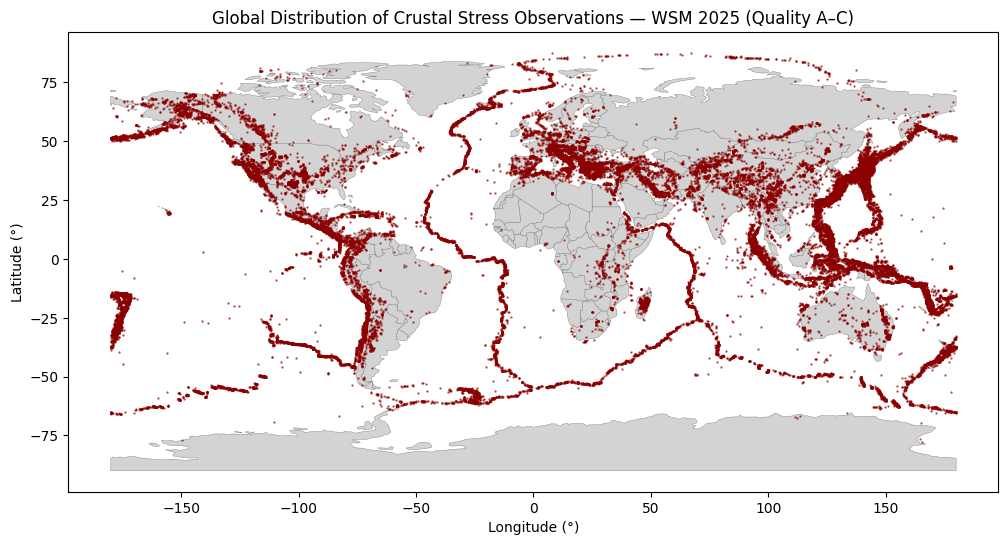

In [3]:
world = gpd.read_file(COUNTRIES_PATH)
if world.crs != gdf.crs:
    world = world.to_crs(gdf.crs)

fig, ax = plt.subplots(figsize=(12, 6))
world.plot(ax=ax, color="lightgray", edgecolor="gray", linewidth=0.3)
gdf.plot(ax=ax, color="darkred", markersize=0.5, alpha=0.6)
ax.set_title("Global Distribution of Crustal Stress Observations — WSM 2025 (Quality A–C)")
ax.set_xlabel("Longitude (°)")
ax.set_ylabel("Latitude (°)")
plt.show()

## 4. Germany and surrounding regions

Select observations using a geographic bounding box of **5–16° E** and **47–55° N**. This geographic window covers Germany and surrounding regions and does not follow national borders. The same quality and azimuth filters from Section 2 apply.

In [4]:
gdf_region = gdf.loc[
    gdf["LAT"].between(47, 55)
    & gdf["LON"].between(5, 16)
].copy()

print(f"Regional observations: {len(gdf_region):,}")
print("Reported stress-regime categories:")
print(gdf_region["REGIME"].value_counts())

Regional observations: 584
Reported stress-regime categories:
REGIME
U     285
SS    173
NF     64
TF     33
NS     17
TS     12
Name: count, dtype: int64


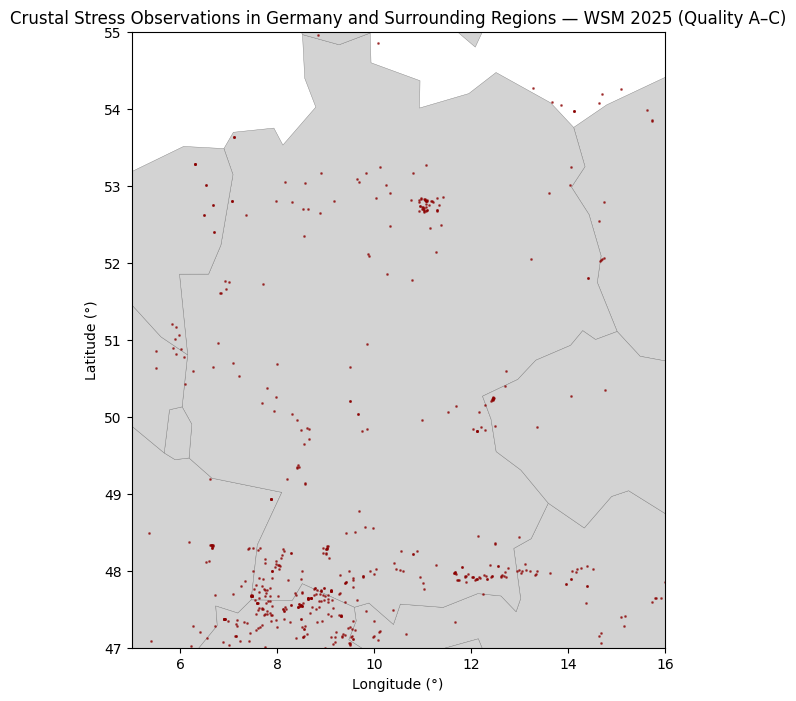

In [5]:
fig, ax = plt.subplots(figsize=(10, 8))
world.plot(ax=ax, color="lightgray", edgecolor="gray", linewidth=0.3)
gdf_region.plot(ax=ax, color="darkred", markersize=1, alpha=0.6)
ax.set_xlim(5, 16)
ax.set_ylim(47, 55)
ax.set_title("Crustal Stress Observations in Germany and Surrounding Regions — WSM 2025 (Quality A–C)")
ax.set_xlabel("Longitude (°)")
ax.set_ylabel("Latitude (°)")
plt.show()

## 5. Project regional observations and basemap

Transform the observation geometries and country boundaries to **EPSG:3035**, a projected European coordinate system measured in meters. `.to_crs()` transforms the geometries; it does **not** modify the original `LAT` and `LON` attribute values. Geographic azimuths must still be interpreted relative to local geographic north.

In [6]:
gdf_region_projected = gdf_region.to_crs(CRS_PROJECTED)
world_projected = world.to_crs(CRS_PROJECTED)

print(f"Regional projected CRS: {gdf_region_projected.crs}")
print(f"Number of observations after projection: {len(gdf_region_projected):,}")
print(gdf_region_projected.geometry.head())

Regional projected CRS: EPSG:3035
Number of observations after projection: 584
153     POINT (4096901.264 3298572.48)
154    POINT (4096474.038 3259598.773)
155    POINT (4029323.612 3095110.174)
156    POINT (4084061.457 3284690.724)
157     POINT (4096901.264 3298572.48)
Name: geometry, dtype: geometry


## 6. Map SHmax orientations

The WSM `AZI` field gives the **SHmax axis orientation clockwise from geographic north**; because this is an axis, it has no arrowhead and is equivalent modulo 180°. Each orientation symbol is drawn using two **geodetic endpoints** on the WGS 84 ellipsoid, obtained at azimuths `AZI` and `AZI + 180°` from the observation. The endpoints and observation center are then projected into EPSG:3035.

Using `Geod.fwd` **before** projection accounts for the fact that geographic north and the map grid's north are not generally identical. Here, `L = 5000` meters is the chosen **symbol half-length** (a 10 km total geodesic span), purely for display. The projected rendered length may differ slightly because of projection scale distortion. The symbol's 5 km half-length does not indicate stress magnitude, depth, quality, or spatial extent of the stress field.

Overlapping observation symbols are retained: multiple database records may share the same geographic coordinates.

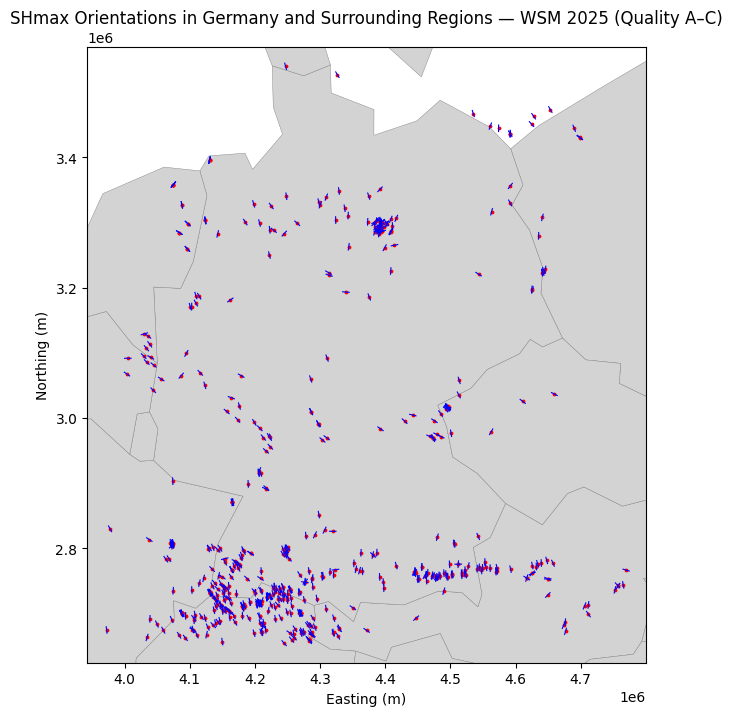

In [7]:
geod = Geod(ellps="WGS84")
transformer = Transformer.from_crs(
    CRS_GEOGRAPHIC, CRS_PROJECTED, always_xy=True
)

L = 5000  # meters: visualization half-length only

fig, ax = plt.subplots(figsize=(10, 8))
world_projected.plot(
    ax=ax, color="lightgray", edgecolor="gray", linewidth=0.3
)

for _, row in gdf_region.iterrows():
    lon = row["LON"]
    lat = row["LAT"]
    azi = row["AZI"]

    # Calculate opposite geodetic endpoints around the same observation.
    lon2, lat2, _ = geod.fwd(lon, lat, azi, L)
    lon1, lat1, _ = geod.fwd(lon, lat, azi + 180, L)

    # Transform endpoints and center to the basemap CRS.
    x1, y1 = transformer.transform(lon1, lat1)
    x2, y2 = transformer.transform(lon2, lat2)
    x_center, y_center = transformer.transform(lon, lat)

    ax.plot([x1, x2], [y1, y2], color="blue", linewidth=0.8)
    ax.scatter(x_center, y_center, color="red", s=3)

min_x, min_y, max_x, max_y = gdf_region_projected.total_bounds
margin_x = 30000  # meters
margin_y = 30000  # meters
ax.set_xlim(min_x - margin_x, max_x + margin_x)
ax.set_ylim(min_y - margin_y, max_y + margin_y)
ax.set_title("SHmax Orientations in Germany and Surrounding Regions — WSM 2025 (Quality A–C)")
ax.set_xlabel("Easting (m)")
ax.set_ylabel("Northing (m)")
ax.set_aspect("equal")
plt.show()

## 7. Check repeated observation locations

Some database observations share identical geographic coordinates. Count repeated coordinate pairs using `.duplicated()` and compare with the number of distinct coordinate pairs. With `keep=False`, select **all** records belonging to repeated-location groups, including the first occurrence in each group.

Repeated coordinates **do not automatically indicate invalid or duplicate measurements**; records may differ by method, depth, orientation, or source. No observations are removed in this notebook.

In [8]:
total_observations = len(gdf_region)
unique_locations = gdf_region[["LAT", "LON"]].drop_duplicates().shape[0]
additional_records_at_existing_locations = gdf_region.duplicated(
    subset=["LAT", "LON"]
).sum()

df_repeated = gdf_region.loc[
    gdf_region.duplicated(subset=["LAT", "LON"], keep=False)
].copy()
records_in_repeated_groups = len(df_repeated)

summary = pd.Series({
    "Total regional observations": total_observations,
    "Unique coordinate pairs": unique_locations,
    "Additional records at previously seen coordinates": additional_records_at_existing_locations,
    "All records in repeated-location groups": records_in_repeated_groups,
    "Records at locations occurring once": total_observations - records_in_repeated_groups,
}, name="Count")
print(summary.to_string())

Total regional observations                          584
Unique coordinate pairs                              524
Additional records at previously seen coordinates     60
All records in repeated-location groups               99
Records at locations occurring once                  485


In [9]:
# Inspect reported attributes before making any decision about repeated locations.
columns_to_review = ["ID", "LAT", "LON", "AZI", "QUALITY", "TYPE", "DEPTH"]
display(df_repeated[columns_to_review].head(10))

,ID,LAT,LON,AZI,QUALITY,TYPE,DEPTH
153,wsm00402,52.750,6.680,130,C,BO,2.20
154,wsm00403,52.400,6.700,135,C,BO,2.20
156,wsm00405,52.620,6.500,120,C,BO,2.20
157,wsm00406,52.750,6.680,130,C,BO,2.20
158,wsm00407,52.400,6.700,135,C,BO,2.20
161,wsm00410,52.620,6.500,120,C,BO,2.20
333,wsm00718,48.233,8.283,125,C,BO,0.27
337,wsm00722,49.816,12.119,158,B,BO,2.75
1640,wsm02501,50.240,12.450,110,C,FMS,9.00
1642,wsm02503,50.230,12.460,133,C,FMS,10.00


## 8. Findings and limitations

### Key findings

- The original database contained **100,842** observations; the quality A–C, valid-coordinate, available-azimuth subset contained **77,364** mapping-ready observations.
- The selected geographic window (**5–16° E, 47–55° N**) contained **584** observations.
- Within these 584 records, there were **524 distinct latitude/longitude pairs**. **60** records repeated a previously seen coordinate pair, while **99** records belonged to repeated-location groups when first occurrences were included; **485** observations occurred at coordinate pairs found only once.
- Recorded observations cluster unevenly. Several records share identical or close positions, which can obscure orientation symbols at the chosen regional scale.
- The plotted SHmax lines communicate **orientation**, not magnitude. Some local orientations look similar, while others differ; a quantitative regional directional analysis is needed before making broader tectonic claims.

### Limitations and interpretation safeguards

1. **Sampling bias:** Observation density depends on where measurements were collected; neither the map nor regime counts prove regional stress intensity or prevalence.
2. **Spatial overlap:** Repeated latitude/longitude values do not automatically imply duplicate measurements. The source references and other attributes need further review before potential deduplication.
3. **Cartographic scale:** A fixed 5 km symbol half-length is arbitrary and can generate overlap. Marker size and line length are display settings, not measured physical quantities.
4. **Projection:** Geodetic endpoints are constructed using geographic azimuths and then projected to EPSG:3035 to avoid directly interpreting azimuths as projected-grid angles.
5. **Study window:** The rectangular extent is a practical local subset rather than a tectonic or political boundary.